In [43]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.16.2
NumPy: 1.26.4


In [44]:

import os

print(os.getcwd())

d:\Tugas Akhir\model\Model_1_Face_Detector\notebook


In [45]:
import os

print(os.listdir())

['testing_blazeface.ipynb']


In [46]:
MODEL_PATH = "../model/face_detection_short_range.tflite"

interpreter = tf.lite.Interpreter(
    model_path=MODEL_PATH
)

interpreter.allocate_tensors()

print("BlazeFace berhasil dimuat")

BlazeFace berhasil dimuat


In [47]:
# Mendapatkan informasi input dan output model

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("===== INPUT MODEL =====")
for i, detail in enumerate(input_details):
    print(f"Input {i}:")
    print(detail)

print("\n===== OUTPUT MODEL =====")
for i, detail in enumerate(output_details):
    print(f"Output {i}:")
    print(detail)

===== INPUT MODEL =====
Input 0:
{'name': 'input', 'index': 0, 'shape': array([  1, 128, 128,   3]), 'shape_signature': array([  1, 128, 128,   3]), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}

===== OUTPUT MODEL =====
Output 0:
{'name': 'regressors', 'index': 175, 'shape': array([  1, 896,  16]), 'shape_signature': array([  1, 896,  16]), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}
Output 1:
{'name': 'classificators', 'index': 174, 'shape': array([  1, 896,   1]), 'shape_signature': array([  1, 896,   1]), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': ar

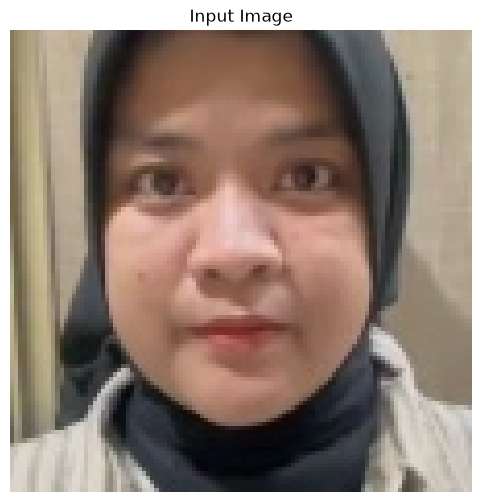

In [48]:
import cv2
import matplotlib.pyplot as plt

IMAGE_PATH = "../data/test1.jpg"

image = cv2.imread(IMAGE_PATH)

# Ubah BGR ke RGB untuk ditampilkan
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Input Image")
plt.show()

In [49]:
# ==========================================
# TAHAP 4 - PREPROCESSING GAMBAR
# ==========================================
# ==========================================
# PREPROCESSING BLAZEFACE (PERBAIKAN)
# ==========================================

# Resize ke ukuran input model
image_resized = cv2.resize(
    image_rgb,
    (128,128)
)


# Konversi ke float32
input_data = image_resized.astype(np.float32)


# Normalisasi sesuai BlazeFace
input_data = (input_data - 127.5) / 127.5


# Tambahkan batch dimension
input_data = np.expand_dims(
    input_data,
    axis=0
)


print("Shape :", input_data.shape)
print("Min :", input_data.min())
print("Max :", input_data.max())

Shape : (1, 128, 128, 3)
Min : -1.0
Max : 0.8980392


In [50]:
# ==========================================
# TAHAP 5 - INFERENCE BLAZEFACE
# ==========================================


# Masukkan data gambar ke input tensor model

interpreter.set_tensor(
    input_details[0]["index"],
    input_data
)


# Jalankan proses prediksi

start_time = time.time()

interpreter.invoke()

end_time = time.time()


# Hitung waktu inference

inference_time = (end_time - start_time) * 1000


print("Inference berhasil")
print(f"Waktu inference: {inference_time:.2f} ms")

Inference berhasil
Waktu inference: 4.02 ms


In [51]:
regressors = interpreter.get_tensor(
    output_details[0]["index"]
)

classificators = interpreter.get_tensor(
    output_details[1]["index"]
)

print("Regressors shape:", regressors.shape)
print("Classificators shape:", classificators.shape)

Regressors shape: (1, 896, 16)
Classificators shape: (1, 896, 1)


In [52]:
# ==========================================
# TAHAP 7 - CEK CONFIDENCE DETEKSI
# ==========================================

scores = classificators[0,:,0]

# Ambil nilai confidence tertinggi

max_score = np.max(scores)

best_index = np.argmax(scores)


print("Confidence tertinggi :", max_score)
print("Index kandidat      :", best_index)

Confidence tertinggi : 2.4864132
Index kandidat      : 683


In [53]:
# ==========================================
# TAHAP 7 - KONVERSI LOGIT MENJADI CONFIDENCE
# ==========================================

def sigmoid(x):
    return 1 / (1 + np.exp(-x))


# Ambil output classificator

scores_raw = classificators[0,:,0]


# Konversi logit menjadi probability

scores = sigmoid(scores_raw)


# Cari confidence tertinggi

max_score = np.max(scores)

best_index = np.argmax(scores)


print("Logit tertinggi      :", scores_raw[best_index])
print("Confidence tertinggi :", max_score)
print("Index kandidat       :", best_index)

Logit tertinggi      : 2.4864132
Confidence tertinggi : 0.92318386
Index kandidat       : 683


In [54]:
CONFIDENCE_THRESHOLD = 0.5


if max_score > CONFIDENCE_THRESHOLD:
    print("✅ Wajah terdeteksi")
else:
    print("❌ Wajah tidak terdeteksi")

✅ Wajah terdeteksi


In [55]:
# Ambil regresi terbaik

best_regressor = regressors[0, best_index]

print(best_regressor)
print("Jumlah nilai:", len(best_regressor))

[ -8.060111    7.3657     87.72917    87.73813   -27.245323  -14.7408695
  10.5965185 -13.258875   -9.816846    6.0281773 -10.140211   26.348387
 -45.47389    -4.743727   31.031788   -2.524708 ]
Jumlah nilai: 16


In [56]:
# ==========================================
# GENERATE BLAZEFACE ANCHORS (CORRECT)
# ==========================================

import numpy as np


def generate_blazeface_anchors():
    
    anchors = []

    input_size = 128

    # feature map size dan jumlah anchor
    configs = [
        (16, 2),
        (8, 6)
    ]

    for feature_size, num_anchors in configs:

        for y in range(feature_size):

            for x in range(feature_size):

                x_center = (x + 0.5) / feature_size
                y_center = (y + 0.5) / feature_size

                for _ in range(num_anchors):

                    anchors.append(
                        [
                            x_center,
                            y_center
                        ]
                    )

    return np.array(anchors)



anchors = generate_blazeface_anchors()


print("Jumlah anchor:", len(anchors))
print("Shape:", anchors.shape)

Jumlah anchor: 896
Shape: (896, 2)


In [57]:
# ==========================================
# DECODE BOUNDING BOX BLAZEFACE
# ==========================================

def decode_box(regressor, anchor):
    
    # Bounding box
    x_center = regressor[0] / 128 + anchor[0]
    y_center = regressor[1] / 128 + anchor[1]

    width = regressor[2] / 128
    height = regressor[3] / 128


    x_min = x_center - width / 2
    y_min = y_center - height / 2

    x_max = x_center + width / 2
    y_max = y_center + height / 2


    return np.array([
        x_min,
        y_min,
        x_max,
        y_max
    ])

In [58]:
# Ambil kandidat terbaik

best_regressor = regressors[0, best_index]

best_anchor = anchors[best_index]


# Decode

box = decode_box(
    best_regressor,
    best_anchor
)


print("Bounding box normalized:")
print(box)

Bounding box normalized:
[0.15683831 0.15231746 0.84222246 0.83777159]


In [59]:
# ==========================================
# KONVERSI BOUNDING BOX KE PIXEL
# ==========================================

h, w, _ = image_rgb.shape


x_min = int(box[0] * w)
y_min = int(box[1] * h)

x_max = int(box[2] * w)
y_max = int(box[3] * h)


print("Ukuran gambar:")
print(w, "x", h)

print("\nBounding box pixel:")
print(
    x_min,
    y_min,
    x_max,
    y_max
)

Ukuran gambar:
112 x 112

Bounding box pixel:
17 17 94 93


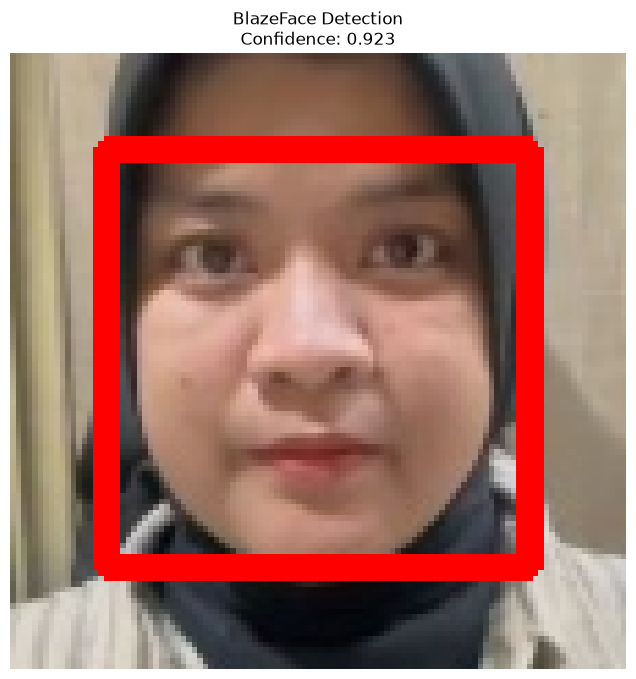

In [60]:
# ==========================================
# VISUALISASI DETEKSI WAJAH
# ==========================================

result_image = image_rgb.copy()


cv2.rectangle(
    result_image,
    (x_min, y_min),
    (x_max, y_max),
    (255,0,0),
    3
)


plt.figure(figsize=(8,8))

plt.imshow(result_image)

plt.axis("off")

plt.title(
    f"BlazeFace Detection\nConfidence: {max_score:.3f}"
)

plt.show()